In [2]:
import wandb
import pandas as pd
api = wandb.Api()

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/pipev/.netrc.


In [6]:
runs = api.runs("pipe-verri-gh/Canonicalization", filters={
    "jobType": "finetuning",
    "group": {"$ne": None}
})

In [7]:
df = pd.DataFrame([
    run.summary._json_dict | {
        "name": run.name,
        "id": run.id,
        "tags": run.tags,
        "group": run.group,
        "downstream_task": run.config.get("dataset", {}).get("dataset_name"),
    }
    for run in runs
])

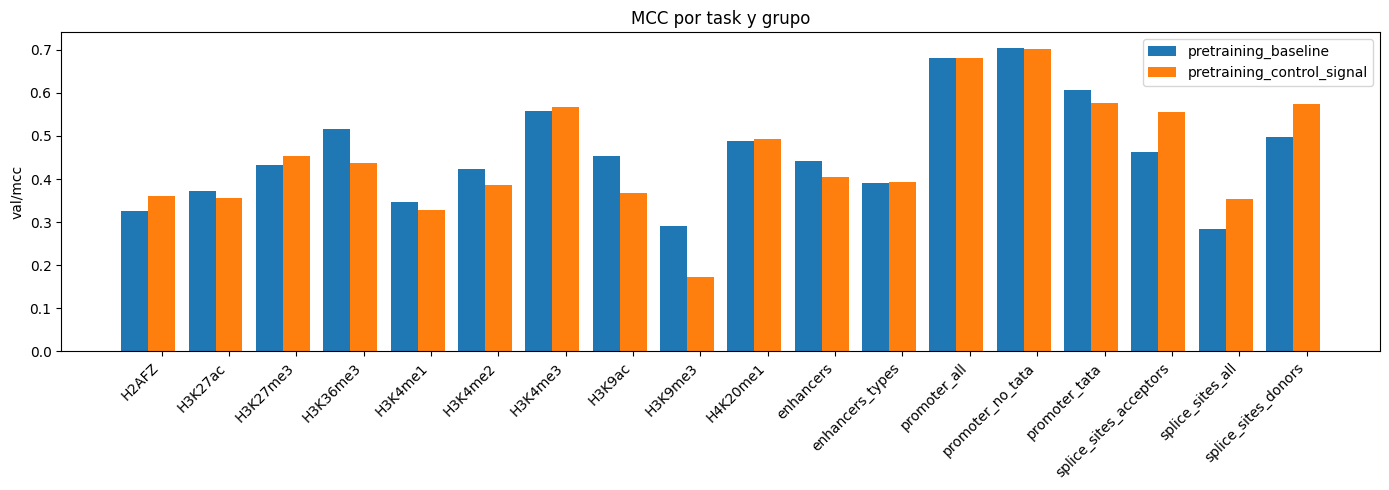

In [8]:
import matplotlib.pyplot as plt
import numpy as np

groups = sorted(df["group"].dropna().unique())
tasks = sorted(df["downstream_task"].dropna().unique())

x = np.arange(len(tasks))
width = 0.8 / len(groups)

fig, ax = plt.subplots(figsize=(14, 5))

for i, group in enumerate(groups):
    vals = [
        df[(df["group"] == group) & (df["downstream_task"] == t)]["val/mcc"].mean()
        for t in tasks
    ]
    ax.bar(x + i * width - width * len(groups) / 2, vals, width, label=group)

ax.set_xticks(x)
ax.set_xticklabels(tasks, rotation=45, ha="right")
ax.set_ylabel("val/mcc")
ax.set_title("MCC por task y grupo")
ax.legend()

plt.tight_layout()
plt.show()